In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("exported_churn_data.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)
df.head()

Dataset loaded successfully!
Dataset Shape: (21, 21)


,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,Churn Flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,complaint count
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,...,0,keshav,India,Maharashtra,Male,1982-04-12,NaN,NaN,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0,2.0
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,...,0,lalita,India,Delhi,Female,1978-02-15,NaN,NaN,NaN,NaN
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,...,0,mohan,India,Nagaland,Male,2001-08-30,NaN,NaN,NaN,NaN
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,1,mira,India,Delhi,Female,1990-05-05,2024-01-20,Y,20.0,1.0


In [2]:

# 1. Dataset size
print("Dataset Shape:", df.shape)

# 2. Column names
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Dataset information
print("\nDataset Information:")
df.info()

# 4. Statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all"))

# 5. Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 6. Duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())


Dataset Shape: (21, 21)

Column Names:
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score', 'Churn Flag', 'customer_name', 'country', 'state', 'gender', 'dob', 'complaint_date', 'escalations', 'csat_score', 'complaint count']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     object 
 1   subscription_start_date  21 non-null     object 
 2   subscription_type        21 non-null     object 
 3   renewal_date             21 non-null     object 
 4   plan_type                21 non-null     object 
 5   contract_type            21 non-null     object 
 6   cancellation_date        6 non-null      object 
 7   cancellation_rea

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,Churn Flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,complaint count
count,21,21,21,21,21,21,6,6,21.000000,21.000000,...,21.000000,21,21,21,21,21,7,7,7.000000,7.000000
unique,21,21,3,21,3,2,6,5,NaN,NaN,...,NaN,21,2,9,2,21,7,2,NaN,NaN
top,0002-ORFBO,2021-03-15,Organic,2025-03-15,Standard,Annual,2024-09-10,Switched to competitor,NaN,NaN,...,NaN,keshav,India,Delhi,Female,1982-04-12,2024-08-28,Y,NaN,NaN
freq,1,1,9,1,9,12,1,2,NaN,NaN,...,NaN,1,19,4,12,1,1,4,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.847143,823.523810,...,0.285714,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42.142857,1.285714
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17.754677,668.913195,...,0.462910,NaN,NaN,NaN,NaN,NaN,NaN,NaN,33.398745,0.487950
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.990000,42.000000,...,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.000000,1.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.990000,240.000000,...,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,22.500000,1.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.990000,640.000000,...,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.000000,1.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.990000,1150.000000,...,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60.000000,1.500000



Missing Values:
customerid                  0
subscription_start_date     0
subscription_type           0
renewal_date                0
plan_type                   0
contract_type               0
cancellation_date          15
cancellation_reason        15
monthly_charges             0
cltv                        0
churn_score                 0
Churn Flag                  0
customer_name               0
country                     0
state                       0
gender                      0
dob                         0
complaint_date             14
escalations                14
csat_score                 14
complaint count            14
dtype: int64

Duplicate Rows: 0


Churn Flag
0    15
1     6
Name: count, dtype: int64


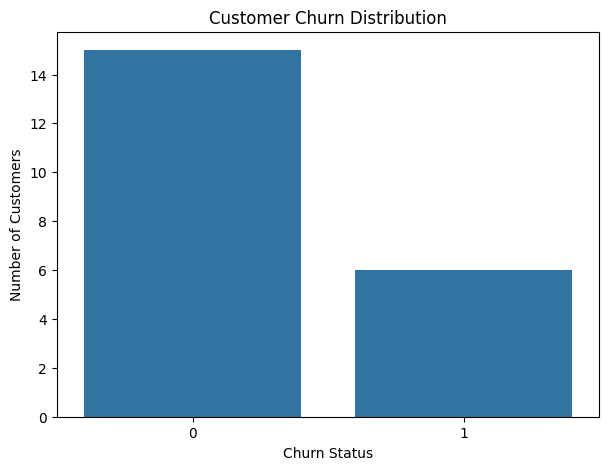

In [5]:


# Check churn categories
print(df["Churn Flag"].value_counts())

# Create the graph
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Churn Flag")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()



In [4]:
print(df.columns.tolist())

['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score', 'Churn Flag', 'customer_name', 'country', 'state', 'gender', 'dob', 'complaint_date', 'escalations', 'csat_score', 'complaint count']


contract_type
Annual     12
Monthly     9
Name: count, dtype: int64


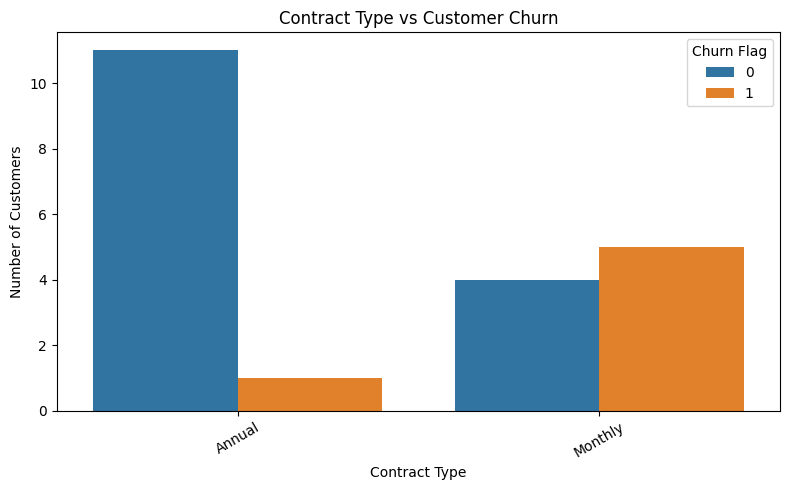

In [6]:

# Check contract types
print(df["contract_type"].value_counts())

# Plot contract type vs churn
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="contract_type",
    hue="Churn Flag"
)

plt.title("Contract Type vs Customer Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.tight_layout()

plt.show()


cancellation_reason
Switched to competitor    2
Too expensive             1
Not enough content        1
Poor streaming quality    1
Forgot to cancel trial    1
Name: count, dtype: int64


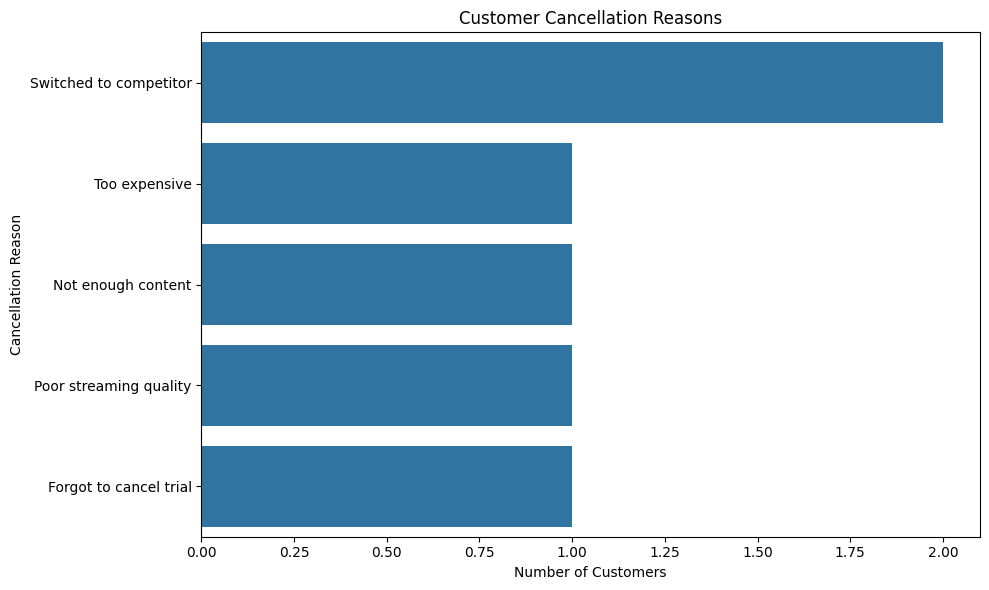

In [7]:

# Check cancellation reasons
print(df["cancellation_reason"].value_counts())

# Create the graph
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    y="cancellation_reason",
    order=df["cancellation_reason"].value_counts().index
)

plt.title("Customer Cancellation Reasons")
plt.xlabel("Number of Customers")
plt.ylabel("Cancellation Reason")
plt.tight_layout()

plt.show()


count    21.000000
mean     18.847143
std      17.754677
min       6.990000
25%      12.990000
50%      13.990000
75%      20.990000
max      92.990000
Name: monthly_charges, dtype: float64


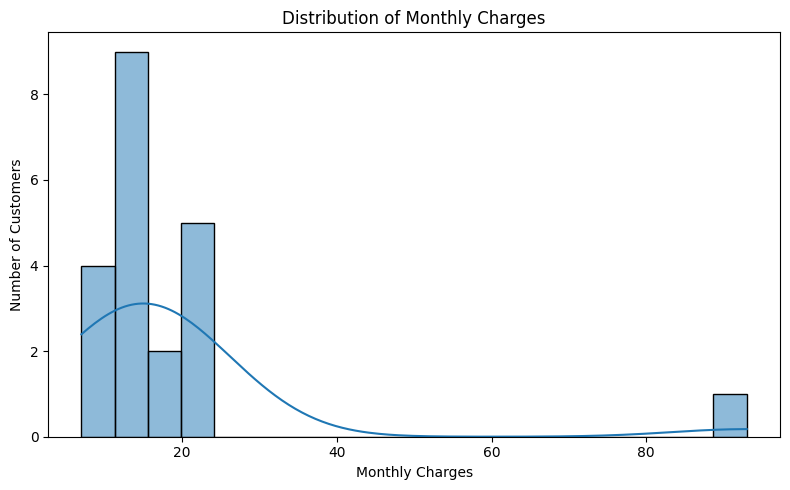

In [8]:

# Check monthly charges statistics
print(df["monthly_charges"].describe())

# Plot monthly charges distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="monthly_charges",
    bins=20,
    kde=True
)

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.show()


count    21.000000
mean     43.285714
std      32.292635
min       3.000000
25%      14.000000
50%      34.000000
75%      76.000000
max      99.000000
Name: churn_score, dtype: float64


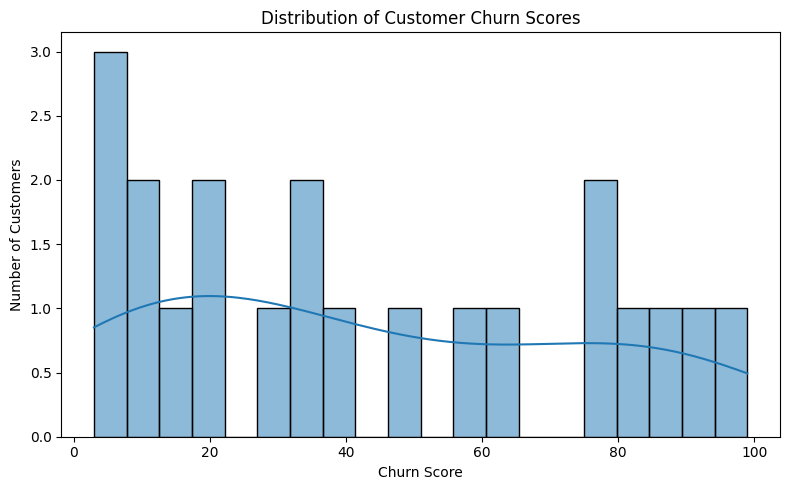

In [9]:

# Check churn score statistics
print(df["churn_score"].describe())

# Plot churn score distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="churn_score",
    bins=20,
    kde=True
)

plt.title("Distribution of Customer Churn Scores")
plt.xlabel("Churn Score")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.show()


In [10]:

print("========== EXPLORATORY DATA ANALYSIS INSIGHTS ==========")

# 1. Dataset size
print("\n1. Dataset Overview")
print("Total Customers:", df.shape[0])
print("Total Columns:", df.shape[1])

# 2. Churn distribution
print("\n2. Churn Distribution")
print(df["Churn Flag"].value_counts())

# 3. Contract type distribution
print("\n3. Contract Type Distribution")
print(df["contract_type"].value_counts())

# 4. Monthly charges
print("\n4. Monthly Charges")
print("Average Monthly Charges:", round(df["monthly_charges"].mean(), 2))
print("Minimum Monthly Charges:", df["monthly_charges"].min())
print("Maximum Monthly Charges:", df["monthly_charges"].max())

# 5. Churn score
print("\n5. Churn Score")
print("Average Churn Score:", round(df["churn_score"].mean(), 2))

# 6. Missing values
print("\n6. Missing Values")
print("Total Missing Values:", df.isnull().sum().sum())

# 7. Duplicate rows
print("\n7. Duplicate Rows")
print("Total Duplicates:", df.duplicated().sum())


========== EXPLORATORY DATA ANALYSIS INSIGHTS ==========

1. Dataset Overview
Total Customers: 21
Total Columns: 21

2. Churn Distribution
Churn Flag
0    15
1     6
Name: count, dtype: int64

3. Contract Type Distribution
contract_type
Annual     12
Monthly     9
Name: count, dtype: int64

4. Monthly Charges
Average Monthly Charges: 18.85
Minimum Monthly Charges: 6.99
Maximum Monthly Charges: 92.99

5. Churn Score
Average Churn Score: 43.29

6. Missing Values
Total Missing Values: 86

7. Duplicate Rows
Total Duplicates: 0


In [11]:

import os

os.makedirs("graphs", exist_ok=True)

print("Graphs folder created successfully!")


Graphs folder created successfully!


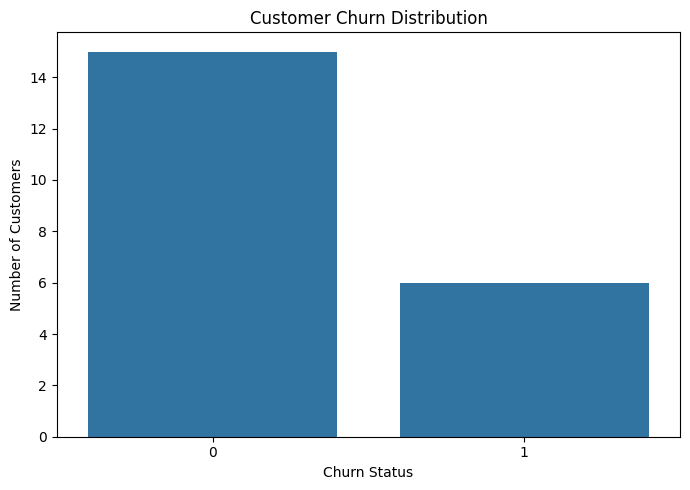

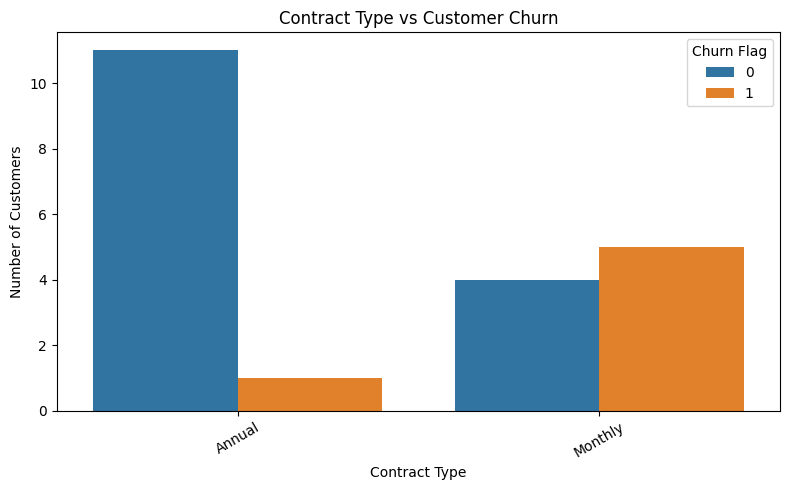

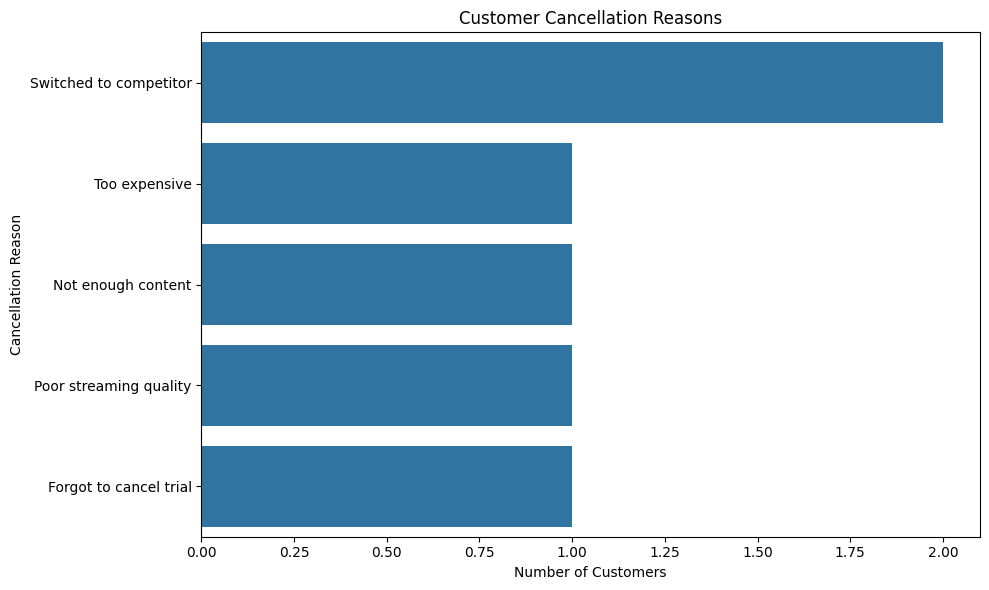

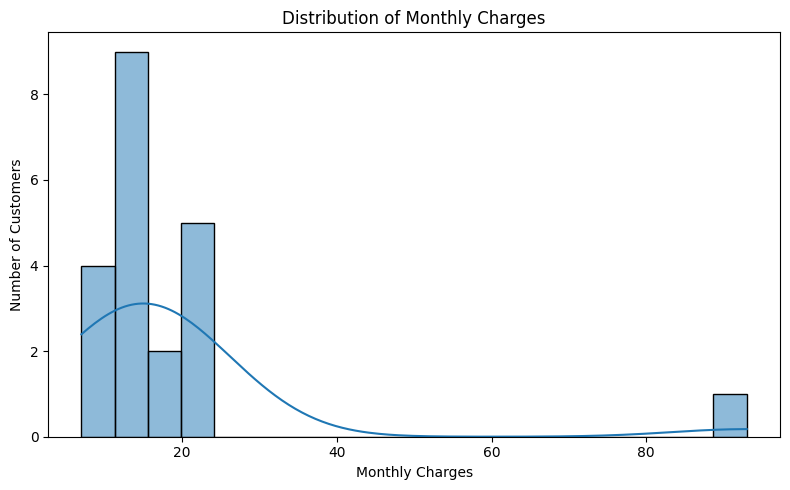

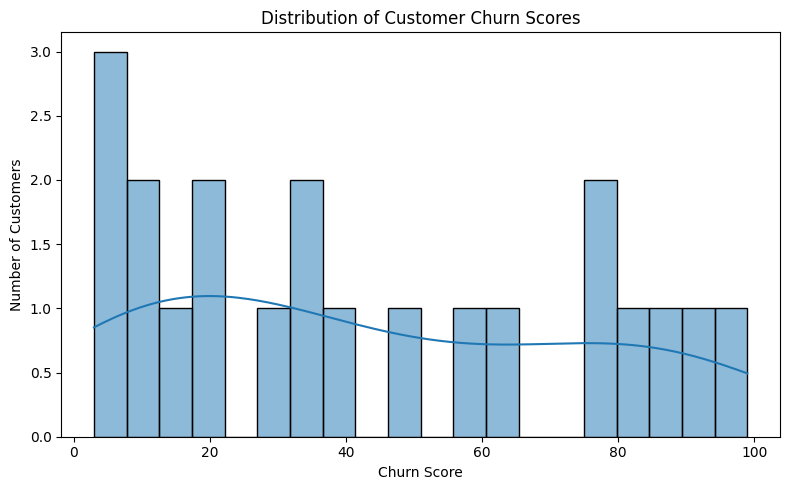

All 5 graphs saved successfully in the graphs folder!


In [12]:

import os
import matplotlib.pyplot as plt
import seaborn as sns

# Create folder to save graphs
os.makedirs("graphs", exist_ok=True)

# Graph 1: Churn Distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Churn Flag")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("graphs/churn_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

# Graph 2: Contract Type vs Churn
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="contract_type", hue="Churn Flag")
plt.title("Contract Type vs Customer Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("graphs/contract_type_vs_churn.png", dpi=300, bbox_inches="tight")
plt.show()

# Graph 3: Cancellation Reasons
plt.figure(figsize=(10, 6))
sns.countplot(
    data=df,
    y="cancellation_reason",
    order=df["cancellation_reason"].value_counts().index
)
plt.title("Customer Cancellation Reasons")
plt.xlabel("Number of Customers")
plt.ylabel("Cancellation Reason")
plt.tight_layout()
plt.savefig("graphs/cancellation_reasons.png", dpi=300, bbox_inches="tight")
plt.show()

# Graph 4: Monthly Charges Distribution
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="monthly_charges", bins=20, kde=True)
plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("graphs/monthly_charges.png", dpi=300, bbox_inches="tight")
plt.show()

# Graph 5: Churn Score Distribution
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="churn_score", bins=20, kde=True)
plt.title("Distribution of Customer Churn Scores")
plt.xlabel("Churn Score")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("graphs/churn_score.png", dpi=300, bbox_inches="tight")
plt.show()

print("All 5 graphs saved successfully in the graphs folder!")
